# Comparação das geometrias
Este notebook contém apenas leitura dos dados `.npz` e plotagem.

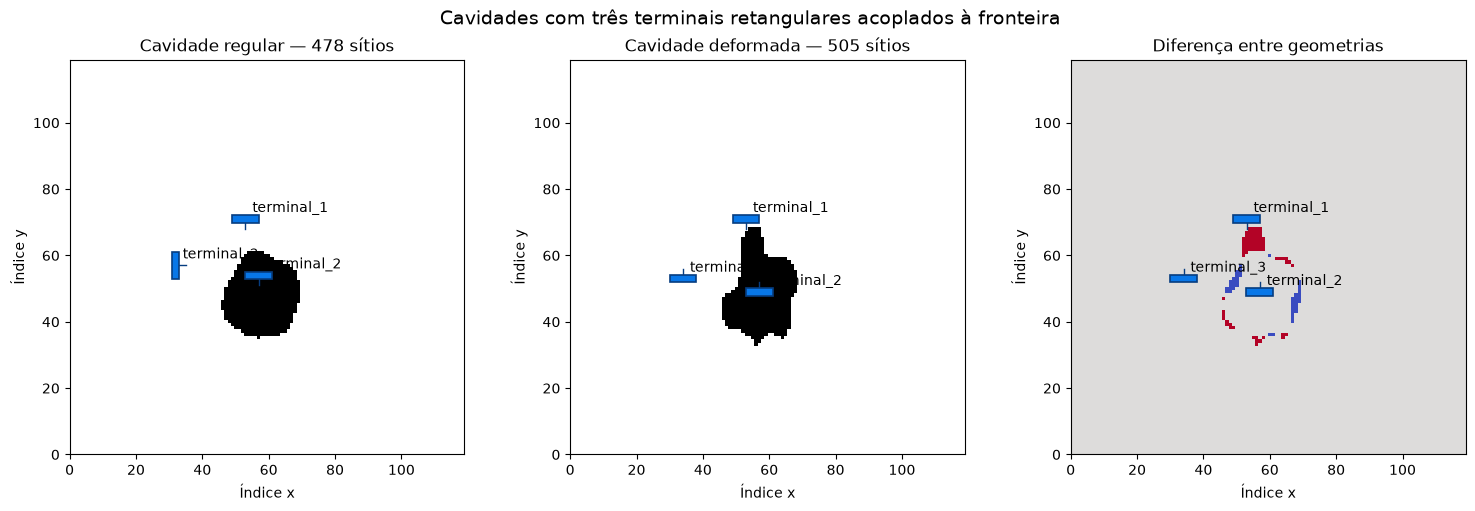

Figura salva em ../figures/geometry_comparison.png


In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

DATA_PATH = Path('../data/geometries.npz')
FIGURES_DIR = Path('../figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with np.load(DATA_PATH) as data:
    regular_mask = data['regular_mask']
    deformed_mask = data['deformed_mask']
    terminal_names = data['terminal_names'].astype(str)
    lattice_size = data['lattice_size']
    regular_count = int(data['regular_site_count'])
    deformed_count = int(data['deformed_site_count'])
    regular_terminals = data['regular_terminal_lattice']
    deformed_terminals = data['deformed_terminal_lattice']
    regular_terminal_normals = data['regular_terminal_normals']
    deformed_terminal_normals = data['deformed_terminal_normals']
    terminal_dimensions = data['terminal_dimensions']

height, width = lattice_size
svg_width, svg_height = 210.0, 297.0

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
geometries = (
    (axes[0], regular_mask, regular_terminals, regular_terminal_normals,
     f'Cavidade regular — {regular_count} sítios'),
    (axes[1], deformed_mask, deformed_terminals, deformed_terminal_normals,
     f'Cavidade deformada — {deformed_count} sítios'),
)


def draw_terminals(ax, terminals, normals):
    """Desenha terminais retangulares sobre as interfaces físicas."""
    for terminal, normal, name, dimensions in zip(
            terminals, normals, terminal_names, terminal_dimensions):
        x, y = terminal

        if abs(normal[1]) >= abs(normal[0]):
            rect_width = dimensions[0] / svg_width * (width - 1)
            rect_height = dimensions[1] / svg_height * (height - 1)
        else:
            rect_width = dimensions[1] / svg_height * (width - 1)
            rect_height = dimensions[0] / svg_width * (height - 1)

        outward = 3.0
        x_out = x + outward * normal[0]
        y_out = y + outward * normal[1]

        rect = Rectangle(
            (x_out - rect_width / 2.0, y_out - rect_height / 2.0),
            rect_width,
            rect_height,
            facecolor='#0877e8',
            edgecolor='#063d80',
            linewidth=1.2,
            zorder=7,
        )
        ax.add_patch(rect)
        ax.plot([x, x_out], [y, y_out], color='#063d80', linewidth=1.0,
                zorder=6)
        ax.annotate(name, (x_out, y_out), xytext=(5, 5),
                    textcoords='offset points', zorder=8)


for ax, mask, terminals, normals, title in geometries:
    ax.imshow(mask.T, origin='lower', cmap='Greys',
              extent=(0, width - 1, 0, height - 1))
    ax.set_aspect('equal')
    ax.set_xlabel('Índice x')
    ax.set_ylabel('Índice y')
    ax.set_title(title)
    draw_terminals(ax, terminals, normals)

difference = deformed_mask.astype(int) - regular_mask.astype(int)
axes[2].imshow(difference.T, origin='lower', cmap='coolwarm', vmin=-1, vmax=1,
               extent=(0, width - 1, 0, height - 1))
axes[2].set_aspect('equal')
axes[2].set_xlabel('Índice x')
axes[2].set_ylabel('Índice y')
axes[2].set_title('Diferença entre geometrias')
draw_terminals(axes[2], deformed_terminals, deformed_terminal_normals)

fig.suptitle('Cavidades com três terminais retangulares acoplados à fronteira', fontsize=14)
output_path = FIGURES_DIR / 'geometry_comparison.png'
fig.savefig(output_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Figura salva em {output_path}')
